In [1]:
! pip -q install numpy pandas matplotlib scikit-learn

## Question 3

This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class-specific mean vector and a class specific covariance matrix. We consider the simple case where $p = 1$, i.e. there is only one feature.

Suppose that we have $K$ classes, and that if an observation belongs to the $k$th class then $X$ comes from a one-dimensional normal distribution, $X \sim N(\mu_k, \sigma_k^2)$. Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is *not* linear. Argue that it is in fact quadratic.

*Hint: For this problem, you should follow the arguments laid out in Section 4.4.1, but without making the assumption that $\sigma_1^2 = \cdots = \sigma_K^2$.*

### 解答

令 $Y$ 表示類別，並令

$$
\pi_k=P(Y=k)
$$

表示第 $k$ 類的先驗機率，其中 $\pi_k>0$ 且 $\sum_{k=1}^{K}\pi_k=1$。

根據題目假設，

$$
X\mid Y=k\sim N(\mu_k,\sigma_k^2),
\qquad \sigma_k^2>0.
$$

所以第 $k$ 類的條件機率密度函數為

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

且

$$
f_{X,Y}(x,k)
=
f_X(x)\,P(Y=k\mid X=x).
$$

因此，

$$
f_X(x)\,P(Y=k\mid X=x)
=
\pi_k f_k(x).
$$

兩邊除以 $f_X(x)>0$，得到

$$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}{f_X(x)}.
$$

然後因為類別之間互斥，所以可以把分母整理成相加形式，得到

$$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}
{\displaystyle\sum_{\ell=1}^{K}\pi_\ell f_\ell(x)}.
$$

Bayes 分類器會將觀測值 $x$ 分到後驗機率最大的類別。由於分母不管 $k$ 怎麼變都一樣，所以只比較分子：

$$
g^*(x)
=
\operatorname*{arg\,max}_{k=1,\ldots,K}
\pi_k f_k(x).
$$

因為對數函數嚴格遞增，取對數不會改變各類別分數的大小順序。因此

$$
g^*(x)
=
\operatorname*{arg\,max}_{k=1,\ldots,K}
\left\{\log\pi_k+\log f_k(x)\right\}.
$$

代入常態密度函數：

$$
\log\pi_k+\log f_k(x)
=
\log\pi_k
-\frac12\log(2\pi)
-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

 $-\frac12\log(2\pi)$ 常數不影響不看刪掉。於是定義判別函數

$$
\delta_k(x)
=
\log\pi_k
-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

分類規則就是選擇 $\delta_k(x)$ 最大的類別：

$$
g^*(x)
=
\operatorname*{arg\,max}_{k=1,\ldots,K}
\delta_k(x).
$$

然後展開平方項可得

$$
\delta_k(x)
=
-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac12\log\sigma_k^2
+\log\pi_k.
$$

這是 $x$ 的二次函數。

當 $\sigma_k^2\neq\sigma_\ell^2$ 時，比較第 $k$ 類與第 $\ell$ 類，相減為

$$
\begin{aligned}
\delta_k(x)-\delta_\ell(x)
={}&
\left(
\frac{1}{2\sigma_\ell^2}
-\frac{1}{2\sigma_k^2}
\right)x^2 \\
&+
\left(
\frac{\mu_k}{\sigma_k^2}
-\frac{\mu_\ell}{\sigma_\ell^2}
\right)x \\
&-\frac{\mu_k^2}{2\sigma_k^2}
+\frac{\mu_\ell^2}{2\sigma_\ell^2}
-\frac12\log\left(
\frac{\sigma_k^2}{\sigma_\ell^2}
\right)
+\log\left(\frac{\pi_k}{\pi_\ell}\right).
\end{aligned}
$$

$x^2$ 的係數不為零，所以比較兩個類別時仍然保留二次項。

所以當各類別具有不同變異數時，Bayes 分類規則需要比較二次函數。

## Question 12

Suppose that you wish to classify an observation $X \in \mathbb{R}$ into `apples` and `oranges`. You fit a logistic regression model and find that

$$
\widehat{\Pr}(Y = \text{orange} \mid X = x)
= \frac{\exp(\hat{\beta}_0 + \hat{\beta}_1 x)}{1 + \exp(\hat{\beta}_0 + \hat{\beta}_1 x)}.
$$

Your friend fits a logistic regression model to the same data using the *softmax* formulation in (4.13), and finds that

$$
\widehat{\Pr}(Y = \text{orange} \mid X = x)
= \frac{\exp(\hat{\alpha}_{\text{orange}0} + \hat{\alpha}_{\text{orange}1}x)}{\exp(\hat{\alpha}_{\text{orange}0} + \hat{\alpha}_{\text{orange}1}x) + \exp(\hat{\alpha}_{\text{apple}0} + \hat{\alpha}_{\text{apple}1}x)}.
$$

### (a)

What is the log odds of `orange` versus `apple` in your model?

### (b)

What is the log odds of `orange` versus `apple` in your friend's model?

### (c)

Suppose that in your model, $\hat{\beta}_0 = 2$ and $\hat{\beta}_1 = -1$. What are the coefficient estimates in your friend's model? Be as specific as possible.

### (d)

Now suppose that you and your friend fit the same two models on a different data set. This time, your friend gets the coefficient estimates $\hat{\alpha}_{\text{orange}0} = 1.2$, $\hat{\alpha}_{\text{orange}1} = -2$, $\hat{\alpha}_{\text{orange}0} = 3$, $\hat{\alpha}_{\text{orange}1} = 0.6$. What are the coefficient estimates in your model?

### (e)

Finally, suppose you apply both models from (d) to a data set with 2,000 test observations. What fraction of the time do you expect the predicted class labels from your model to agree with those from your friend's model? Explain your answer.

### (a) 解答

令

$$
\hat p(x)
=
\widehat P(Y=\text{orange}\mid X=x)
=
\frac{\exp(\hat\beta_0+\hat\beta_1x)}
{1+\exp(\hat\beta_0+\hat\beta_1x)}.
$$

因為只有 orange 與 apple 兩個類別，所以

$$
\widehat P(Y=\text{apple}\mid X=x)
=
1-\hat p(x)
=
\frac{1}{1+\exp(\hat\beta_0+\hat\beta_1x)}.
$$

因此，orange 相對於 apple 的勝算（odds）為

$$
\boxed{
\log\frac{\hat p(x)}{1-\hat p(x)}
=
\hat\beta_0+\hat\beta_1x
}.
$$

### (b) 解答

朋友使用 softmax 模型，因此 orange 的預測機率為

$$
\widehat P(Y=\text{orange}\mid X=x)
=
\frac{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
}{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
+
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x)
}.
$$

而 apple 的預測機率為

$$
\widehat P(Y=\text{apple}\mid X=x)
=
\frac{
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x)
}{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
+
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x)
}.
$$

orange 相對於 apple 的 odds，是兩個預測機率的比值。由於兩者分母相同，相除後可得

$$
\frac{
\widehat P(Y=\text{orange}\mid X=x)
}{
\widehat P(Y=\text{apple}\mid X=x)
}
=
\frac{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
}{
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x)
}.
$$

取自然對數，並利用 $\log(A/B)=\log A-\log B$，得到

$$
\begin{aligned}
\log
\frac{
\widehat P(Y=\text{orange}\mid X=x)
}{
\widehat P(Y=\text{apple}\mid X=x)
}
&=
\log\exp(
\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x
)\\
&\quad-
\log\exp(
\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x
)\\
&=
\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x
-\hat\alpha_{\mathrm{apple}0}
-\hat\alpha_{\mathrm{apple}1}x.
\end{aligned}
$$

因此，朋友模型的 log odds 為

$$
\boxed{
\left(
\hat\alpha_{\mathrm{orange}0}
-\hat\alpha_{\mathrm{apple}0}
\right)
+
\left(
\hat\alpha_{\mathrm{orange}1}
-\hat\alpha_{\mathrm{apple}1}
\right)x
}.
$$

### (c) 解答

已知

$$
\hat\beta_0=2,
\qquad
\hat\beta_1=-1.
$$

根據前面的對應關係，只能確定

$$
\hat\alpha_{\mathrm{orange}0}
-\hat\alpha_{\mathrm{apple}0}
=2,
$$

$$
\hat\alpha_{\mathrm{orange}1}
-\hat\alpha_{\mathrm{apple}1}
=-1.
$$

阿四個參數兩條式子明顯不能搞出唯一解，所以寫成

$$
\boxed{
\begin{aligned}
\hat\alpha_{\mathrm{apple}0}&=a,\\
\hat\alpha_{\mathrm{apple}1}&=b,\\
\hat\alpha_{\mathrm{orange}0}&=a+2,\\
\hat\alpha_{\mathrm{orange}1}&=b-1,
\end{aligned}
\qquad a,b\in\mathbb R.
}
$$

因為 softmax 機率只取決於兩類係數的差，而不是四個係數各自的數值。

### (d) 解答

**python 版本的寫錯下標了應為**

$$
\hat\alpha_{\mathrm{orange}0}=1.2,
\qquad
\hat\alpha_{\mathrm{orange}1}=-2,
$$

$$
\hat\alpha_{\mathrm{apple}0}=3,
\qquad
\hat\alpha_{\mathrm{apple}1}=0.6.
$$

所以由係數對應關係可得

$$
\hat\beta_0
=
\hat\alpha_{\mathrm{orange}0}
-\hat\alpha_{\mathrm{apple}0}
=
1.2-3
=
-1.8,
$$

$$
\hat\beta_1
=
\hat\alpha_{\mathrm{orange}1}
-\hat\alpha_{\mathrm{apple}1}
=
-2-0.6
=
-2.6.
$$

因此，

$$
\boxed{
\hat\beta_0=-1.8,
\qquad
\hat\beta_1=-2.6.
}
$$

對應的 logistic regression 模型為

$$
\widehat P(Y=\text{orange}\mid X=x)
=
\frac{\exp(-1.8-2.6x)}
{1+\exp(-1.8-2.6x)}.
$$

### (e) 解答

朋友的 softmax 模型為

$$
\widehat P_{\mathrm{friend}}(Y=\text{orange}\mid X=x)
=
\frac{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
}{
\exp(\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x)
+
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x)
}.
$$

將分子、分母同除以

$$
\exp(\hat\alpha_{\mathrm{apple}0}
+\hat\alpha_{\mathrm{apple}1}x),
$$

可得

$$
\widehat P_{\mathrm{friend}}(Y=\text{orange}\mid X=x)
=
\frac{
\exp\left[
\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x
-\hat\alpha_{\mathrm{apple}0}
-\hat\alpha_{\mathrm{apple}1}x
\right]
}{
1+
\exp\left[
\hat\alpha_{\mathrm{orange}0}
+\hat\alpha_{\mathrm{orange}1}x
-\hat\alpha_{\mathrm{apple}0}
-\hat\alpha_{\mathrm{apple}1}x
\right]
}.
$$

整理後得到

$$
\widehat P_{\mathrm{friend}}(Y=\text{orange}\mid X=x)
=
\frac{
\exp\left[
(\hat\alpha_{\mathrm{orange}0}
-\hat\alpha_{\mathrm{apple}0})
+
(\hat\alpha_{\mathrm{orange}1}
-\hat\alpha_{\mathrm{apple}1})x
\right]
}{
1+
\exp\left[
(\hat\alpha_{\mathrm{orange}0}
-\hat\alpha_{\mathrm{apple}0})
+
(\hat\alpha_{\mathrm{orange}1}
-\hat\alpha_{\mathrm{apple}1})x
\right]
}.
$$

代入數值可得

$$
\begin{aligned}
\widehat P_{\mathrm{friend}}(Y=\text{orange}\mid X=x)
&=
\frac{
\exp\left[(1.2-3)+(-2-0.6)x\right]
}{
1+\exp\left[(1.2-3)+(-2-0.6)x\right]
}\\
&=
\frac{\exp(-1.8-2.6x)}
{1+\exp(-1.8-2.6x)}.
\end{aligned}
$$

而在 (d) 中，自己的 logistic regression 係數為

$$
\hat\beta_0=-1.8,
\qquad
\hat\beta_1=-2.6.
$$

因此，自己的模型也給出

$$
\widehat P_{\mathrm{your}}(Y=\text{orange}\mid X=x)
=
\frac{\exp(-1.8-2.6x)}
{1+\exp(-1.8-2.6x)}.
$$

可以看到對於任何相同的 $x$，兩個模型都會給出完全相同的預測機率。所以只要採用相同的分類門檻與平手處理方式，兩個模型對全部 2,000 筆測試資料都會給出相同的類別預測。

所以預測一致的比例為

$$
\boxed{
\frac{2000}{2000}=1=100\%.
}
$$


## Question 14

In this problem, you will develop a model to predict whether a given car gets high or low gas mileage based on the `Auto` data set.

### (a)

Create a binary variable, `mpg01`, that contains a 1 if `mpg` contains a value above its median, and a 0 if `mpg` contains a value below its median. You can compute the median using the `median()` method of the data frame. Note you may find it helpful to add a column `mpg01` to the data frame by assignment. Assuming you have stored the data frame as `Auto`, this can be done as follows:

```python
Auto['mpg01'] = mpg01
```

### (b)

Explore the data graphically in order to investigate the association between `mpg01` and the other features. Which of the other features seem most likely to be useful in predicting `mpg01`? Scatterplots and boxplots may be useful tools to answer this question. Describe your findings.

### (c)

Split the data into a training set and a test set.

### (d)

Perform LDA on the training data in order to predict `mpg01` using the variables that seemed most associated with `mpg01` in (b). What is the test error of the model obtained?

### (e)

Perform QDA on the training data in order to predict `mpg01` using the variables that seemed most associated with `mpg01` in (b). What is the test error of the model obtained?

### (f)

Perform logistic regression on the training data in order to predict `mpg01` using the variables that seemed most associated with `mpg01` in (b). What is the test error of the model obtained?

### (g)

Perform naive Bayes on the training data in order to predict `mpg01` using the variables that seemed most associated with `mpg01` in (b). What is the test error of the model obtained?

### (h)

Perform KNN on the training data, with several values of $K$, in order to predict `mpg01`. Use only the variables that seemed most associated with `mpg01` in (b). What test errors do you obtain? Which value of $K$ seems to perform the best on this data set?

### (a) 解答

首先，將資料中的 `?` 視為缺失值，並刪除含有缺失值的觀測資料。清理後共有 392 筆資料。

`mpg` 表示每加侖燃料可行駛的英里數，因此數值越高，代表車輛越省油。

清理後的 `mpg` 中位數為 22.75。依照題意，定義

$$
\mathrm{mpg01}_i
=
\begin{cases}
1, & \mathrm{mpg}_i>22.75,\\
0, & \mathrm{mpg}_i\leq22.75.
\end{cases}
$$

因此，`mpg01 = 1` 表示較省油的車輛，`mpg01 = 0` 表示較耗油的車輛。

建立變數後，兩個類別各有 196 筆資料。

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 讀取資料，將 ? 視為缺失值
Auto = pd.read_csv("data/Auto.csv", na_values="?")

n_before = len(Auto)

# 刪除含有缺失值的資料
Auto = Auto.dropna().reset_index(drop=True)

# 計算中位數並建立二元變數
mpg_median = Auto["mpg"].median()
Auto["mpg01"] = (Auto["mpg"] > mpg_median).astype(int)

print(f"原始資料筆數：{n_before}")
print(f"清理後資料筆數：{len(Auto)}")
print(f"mpg 中位數：{mpg_median}")
print("\nmpg01 各類別筆數：")
print(Auto["mpg01"].value_counts().sort_index())
print(Auto.dtypes)

原始資料筆數：397
清理後資料筆數：392
mpg 中位數：22.75

mpg01 各類別筆數：
mpg01
0    196
1    196
Name: count, dtype: int64
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
year              int64
origin            int64
name             object
mpg01             int64
dtype: object


### (b) 解答

使用箱型圖比較兩個類別的特徵分布，並利用散佈圖觀察車重、馬力與 `mpg01` 的關係。此外，使用堆疊長條圖比較不同產地的類別比例。

由圖形可觀察到：

1. **cylinders**：較省油的車輛通常具有較少的汽缸。
2. **displacement**：較省油的車輛通常具有較小的排氣量。
3. **horsepower**：較省油的車輛通常具有較低的馬力。
4. **weight**：較省油的車輛通常較輕。
5. **year**：較省油的車輛傾向來自較新的年份。
6. **acceleration**：較省油的車中位數加速比較差，但分布上仍有明顯重疊。
7. **origin**：美國車中約有 29.4% 屬於高 mpg 組，歐洲車約為 79.4%，日本車約為 88.6%。各產地的類別比例有所差異，顯示產地也可能具有預測能力。

綜合箱型圖、散佈圖與產地比例長條圖，本次選擇與 `mpg01` 呈現明顯關聯的六個特徵：

- `cylinders`
- `displacement`
- `horsepower`
- `weight`
- `year`
- `origin`

其中，汽缸數、排氣量、馬力與車重在兩組之間呈現明顯的分布差異；高 mpg 組的車輛年份通常較新，而不同產地的高 mpg 車輛比例也有所不同，因此將 `year` 與 `origin` 一併納入。

後續各模型皆使用相同的六個原始特徵，以便比較。其中，`origin` 為類別變數，將轉換為虛擬變數後再建立模型。

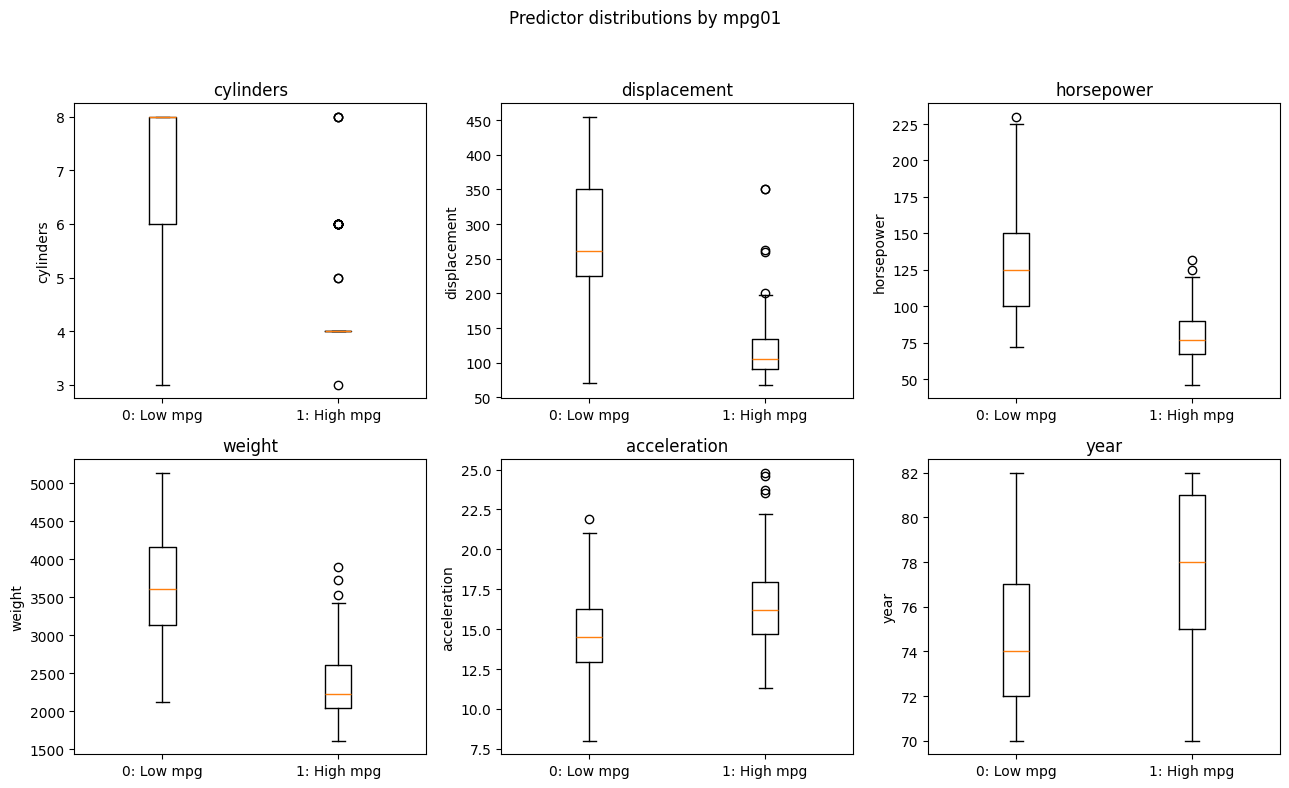

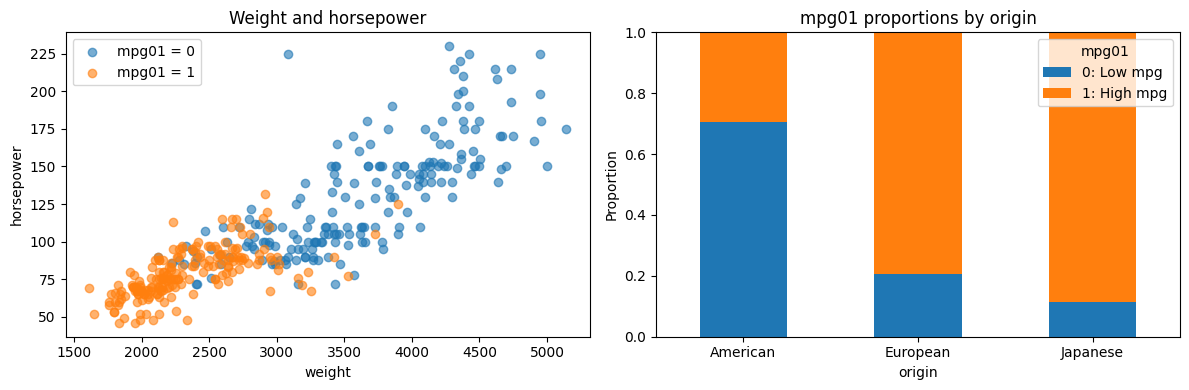

各產地的車輛數與高 mpg 比例：
        total  high_mpg high_mpg_rate
origin                               
1         245        72        29.39%
2          68        54        79.41%
3          79        70        88.61%


In [ ]:
# 1. 六個數值特徵的箱型圖：2 × 3
numeric_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "year",
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, feature in zip(axes.flat, numeric_features):
    grouped_values = [
        Auto.loc[Auto["mpg01"] == 0, feature],
        Auto.loc[Auto["mpg01"] == 1, feature],
    ]

    ax.boxplot(grouped_values)
    ax.set_xticks([1, 2], ["0: Low mpg", "1: High mpg"])
    ax.set_title(feature)
    ax.set_ylabel(feature)

fig.suptitle("Predictor distributions by mpg01")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 2. 計算各產地內 mpg01 的類別比例
origin_proportions = pd.crosstab(
    Auto["origin"],
    Auto["mpg01"],
    normalize="index",
)

# 3. 車重與馬力散佈圖，以及產地比例長條圖
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左圖：車重與馬力，依 mpg01 區分顏色
for group, color in [(0, "tab:blue"), (1, "tab:orange")]:
    subset = Auto.loc[Auto["mpg01"] == group]

    axes[0].scatter(
        subset["weight"],
        subset["horsepower"],
        label=f"mpg01 = {group}",
        color=color,
        alpha=0.6,
    )

axes[0].set(
    xlabel="weight",
    ylabel="horsepower",
    title="Weight and horsepower",
)
axes[0].legend()

# 右圖：每個產地內，低 mpg 與高 mpg 車輛的比例
origin_proportions.plot.bar(
    stacked=True,
    ax=axes[1],
    color=["tab:blue", "tab:orange"],
    rot=0,
)

origin_names = {
    1: "American",
    2: "European",
    3: "Japanese",
}

axes[1].set_xticklabels([
    origin_names[code]
    for code in origin_proportions.index
])

axes[1].set(
    xlabel="origin",
    ylabel="Proportion",
    title="mpg01 proportions by origin",
    ylim=(0, 1),
)
axes[1].legend(
    title="mpg01",
    labels=["0: Low mpg", "1: High mpg"],
)

fig.tight_layout()
plt.show()

# 4. 顯示各產地的車輛數與高 mpg 比例
origin_summary = Auto.groupby("origin")["mpg01"].agg(
    total="count",
    high_mpg="sum",
    high_mpg_rate="mean",
)

print("各產地的車輛數與高 mpg 比例：")
print(
    origin_summary.to_string(
        formatters={"high_mpg_rate": "{:.2%}".format}
    )
)

### (c) 解答

用 (b) 選定的六個原始特徵：

- `cylinders`
- `displacement`
- `horsepower`
- `weight`
- `year`
- `origin`

其中，`origin` 為類別變數，因此以美國（`origin = 1`）為基準類別，建立兩個虛擬變數：

| 產地 | origin_2 | origin_3 |
|---|---:|---:|
| 美國（1） | 0 | 0 |
| 歐洲（2） | 1 | 0 |
| 日本（3） | 0 | 1 |

因此，六個原始特徵經過編碼後，實際形成七個模型輸入欄位：五個數值特徵與兩個產地虛擬變數。

保留兩個產地虛擬變數即可完整表示三種產地，同時避免三個虛擬變數加總恆為 1，造成共變異數矩陣奇異。

接著，將資料隨機分為 70% 的訓練集與 30% 的測試集，設定 `random_state = 42` 以便重現結果，並使用分層抽樣維持類別比例。

切分結果為：

- 訓練集：274 筆，兩個類別各有 137 筆。
- 測試集：118 筆，兩個類別各有 59 筆。

後續所有模型皆使用相同的資料切分與輸入欄位，並以測試錯誤率進行比較：

$$
\text{測試錯誤率}
=
\frac{\text{測試集中分類錯誤的筆數}}
{\text{測試集總筆數}}.
$$

In [9]:
from sklearn.model_selection import train_test_split

# 六個原始特徵
features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "year",
    "origin",
]

X = Auto[features].copy()
y = Auto["mpg01"].copy()

# 明確指定產地類別與順序，讓 origin = 1 成為基準類別
X["origin"] = pd.Categorical(
    X["origin"],
    categories=[1, 2, 3],
)

# 建立 origin_2、origin_3，移除基準類別 origin_1
X = pd.get_dummies(
    X,
    columns=["origin"],
    drop_first=True,
    dtype=int,
)

# 切分訓練集與測試集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("編碼後的模型輸入欄位：")
print(X.columns.tolist())

print(f"\n訓練集形狀：{X_train.shape}")
print(f"測試集形狀：{X_test.shape}")

class_counts = pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).sort_index()

print("\n各資料集的類別筆數：")
print(class_counts)

# 保存各模型的測試錯誤率
model_errors = {}

編碼後的模型輸入欄位：
['cylinders', 'displacement', 'horsepower', 'weight', 'year', 'origin_2', 'origin_3']

訓練集形狀：(274, 7)
測試集形狀：(118, 7)

各資料集的類別筆數：
       train  test
mpg01             
0        137    59
1        137    59


### (d) 解答

使用 (c) 建立的七個輸入欄位，在訓練集上配適 LDA 模型。

LDA 允許不同類別具有不同的平均向量，但假設各類別共用同一個共變異數矩陣，因此得到線性的判別規則。

由於輸入包含產地虛擬變數，類別內的多變量常態假設在此屬於模型近似。

在本次資料切分下，LDA 對 118 筆測試資料中的 9 筆做出錯誤分類，因此測試錯誤率為

$$
\boxed{
\frac{9}{118}
\approx 0.0763
=
7.63\%.
}
$$

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()

# 使用訓練集配適
lda.fit(X_train, y_train)

# 預測測試集
lda_pred = lda.predict(X_test)

lda_wrong = int(np.sum(lda_pred != y_test.to_numpy()))
lda_error = lda_wrong / len(y_test)

model_errors["LDA"] = lda_error

print(f"錯誤分類筆數：{lda_wrong}/{len(y_test)}")
print(f"LDA 測試錯誤率：{lda_error:.2%}")

錯誤分類筆數：9/118
LDA 測試錯誤率：7.63%


### (e) 使用 QDA 預測 mpg01

使用與 LDA 相同的訓練集及七個輸入欄位，建立 QDA 模型。

QDA 允許不同類別具有不同的平均向量與共變異數矩陣，因此判別規則一般為二次的。與 LDA 相同，包含產地虛擬變數時，其常態分布假設屬於模型近似。

在本次資料切分下，QDA 對 118 筆測試資料中的 11 筆做出錯誤分類，因此測試錯誤率為

$$
\boxed{
\frac{11}{118}
\approx 0.0932
=
9.32\%.
}
$$

本次 QDA 的測試錯誤率高於 LDA，表示在這次資料切分下，較有彈性的分類規則並未帶來較好的測試表現。

In [11]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

qda_pred = qda.predict(X_test)

qda_wrong = int(np.sum(qda_pred != y_test.to_numpy()))
qda_error = qda_wrong / len(y_test)

model_errors["QDA"] = qda_error

print(f"錯誤分類筆數：{qda_wrong}/{len(y_test)}")
print(f"QDA 測試錯誤率：{qda_error:.2%}")

錯誤分類筆數：11/118
QDA 測試錯誤率：9.32%


### (f) 解答

使用相同的七個輸入欄位建立 logistic regression 模型，估計車輛屬於 `mpg01 = 1` 的機率，並以 0.5 作為分類門檻。

為改善數值最佳化的穩定性，使用 `StandardScaler` 標準化輸入欄位。標準化所需的平均數與標準差只由訓練集估計，再套用至測試集。

本題使用不含正則化懲罰的 logistic regression，因此設定 `penalty=None`。

在本次資料切分下，模型對 118 筆測試資料中的 8 筆做出錯誤分類，因此測試錯誤率為

$$
\boxed{
\frac{8}{118}
\approx 0.0678
=
6.78\%.
}
$$

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty=None,
        max_iter=5000,
    ),
)

# 標準化參數與模型係數皆只由訓練集估計
logistic.fit(X_train, y_train)

logistic_pred = logistic.predict(X_test)

logistic_wrong = int(
    np.sum(logistic_pred != y_test.to_numpy())
)
logistic_error = logistic_wrong / len(y_test)

model_errors["Logistic regression"] = logistic_error

print(f"錯誤分類筆數：{logistic_wrong}/{len(y_test)}")
print(f"Logistic regression 測試錯誤率：{logistic_error:.2%}")

錯誤分類筆數：8/118
Logistic regression 測試錯誤率：6.78%


### (h) 解答

使用相同的七個輸入欄位建立 KNN 分類器，並比較 K 值：

$$
K=1,3,5,\ldots,25.
$$

KNN 依據觀測值之間的距離尋找鄰居，因此先將七個變數標準化，避免車重等數值尺度較大的欄位主導距離計算。

標準化參數只由訓練集估計，再套用至測試集。每個 K 值皆使用相同的資料切分。

本次測試結果如下：

| K | 錯誤分類筆數 | 測試錯誤率 |
|---:|---:|---:|
| 1 | 11 | 9.32% |
| 3 | 8 | 6.78% |
| 5 | 8 | 6.78% |
| 7 | 10 | 8.47% |
| 9 | 10 | 8.47% |
| 11 | 10 | 8.47% |
| 13 | 10 | 8.47% |
| 15 | 11 | 9.32% |
| 17 | 11 | 9.32% |
| 19 | 11 | 9.32% |
| 21 | 10 | 8.47% |
| 23 | 10 | 8.47% |
| 25 | 10 | 8.47% |

在本次資料切分與所比較的 K 值中，$K=3$ 與 $K=5$ 並列最佳，測試錯誤率皆為

$$
\boxed{
\frac{8}{118}
\approx 0.0678
=
6.78\%.
}
$$

因此，不能說本次只有一個最佳 K 值；$K=3$ 與 $K=5$ 的錯誤分類筆數相同，但不一定錯在相同的觀測資料上。

這裡依題目要求比較不同 K 值的測試錯誤率。若正式選擇模型參數，應使用訓練集內的交叉驗證選擇 K，再用保留的測試集評估最終模型。

不同 K 值的測試結果：
 K  wrong test_error
 1     11      9.32%
 3      8      6.78%
 5      8      6.78%
 7     10      8.47%
 9     10      8.47%
11     10      8.47%
13     10      8.47%
15     11      9.32%
17     11      9.32%
19     11      9.32%
21     10      8.47%
23     10      8.47%
25     10      8.47%

本次測試錯誤率最低的 K：[3, 5]
最低測試錯誤率：6.78%


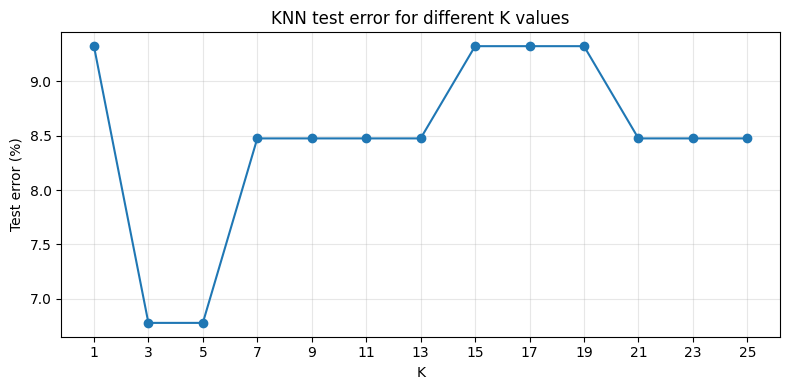


各模型測試錯誤率比較：
                    test_error
KNN (K=3)                6.78%
Logistic regression      6.78%
KNN (K=5)                6.78%
LDA                      7.63%
QDA                      9.32%


In [14]:
from sklearn.neighbors import KNeighborsClassifier

k_values = list(range(1, 26, 2))
knn_rows = []

for k in k_values:
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k),
    )

    # 每次都只使用訓練集配適
    knn.fit(X_train, y_train)
    knn_pred = knn.predict(X_test)

    wrong = int(np.sum(knn_pred != y_test.to_numpy()))
    test_error = wrong / len(y_test)

    knn_rows.append({
        "K": k,
        "wrong": wrong,
        "test_error": test_error,
    })

knn_results = pd.DataFrame(knn_rows)

print("不同 K 值的測試結果：")
print(
    knn_results.to_string(
        index=False,
        formatters={"test_error": "{:.2%}".format},
    )
)

# 找出所有並列最低錯誤率的 K
best_error = knn_results["test_error"].min()

best_ks = knn_results.loc[
    np.isclose(knn_results["test_error"], best_error),
    "K",
].tolist()

print(f"\n本次測試錯誤率最低的 K：{best_ks}")
print(f"最低測試錯誤率：{best_error:.2%}")

# 繪製 K 與測試錯誤率的關係
plt.figure(figsize=(8, 4))

plt.plot(
    knn_results["K"],
    knn_results["test_error"] * 100,
    marker="o",
)

plt.xticks(k_values)
plt.xlabel("K")
plt.ylabel("Test error (%)")
plt.title("KNN test error for different K values")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 將所有並列最佳的 KNN 結果加入模型比較
for k in best_ks:
    model_errors[f"KNN (K={k})"] = best_error

comparison = (
    pd.Series(model_errors, name="test_error")
    .sort_values()
    .to_frame()
)

print("\n各模型測試錯誤率比較：")
print(
    comparison.to_string(
        formatters={"test_error": "{:.2%}".format},
    )
)